## Build a single-layer artificial neural network for a simple classification problem.

## Load and Explore the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 395
Number of columns: 33


In [6]:
print("Dataset columns:")
print(data.columns.tolist())

Dataset columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [8]:
print("Missing values in each column:")
print(data.isnull().sum())

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [9]:
data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


## Prepare the Classification Dataset

In [10]:
required_columns = ["G1", "G2", "studytime", "absences", "G3"]

missing_columns = [
    col for col in required_columns if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Your dataset is missing these required columns: {missing_columns}"
    )

student_data = data[required_columns].copy()

student_data.head()

,G1,G2,studytime,absences,G3
0,5,6,2,6,6
1,5,5,2,4,6
2,7,8,2,10,10
3,15,14,3,2,15
4,6,10,2,4,10


In [12]:
student_data["Pass_Fail"] = (
    student_data["G3"] >= 10
).astype(int)

student_data.head()

,G1,G2,studytime,absences,G3,Pass_Fail
0,5,6,2,6,6,0
1,5,5,2,4,6,0
2,7,8,2,10,10,1
3,15,14,3,2,15,1
4,6,10,2,4,10,1


In [13]:
print("Pass/Fail distribution:")
print(student_data["Pass_Fail"].value_counts())

print("\n0 = Fail")
print("1 = Pass")

Pass/Fail distribution:
Pass_Fail
1    265
0    130
Name: count, dtype: int64

0 = Fail
1 = Pass


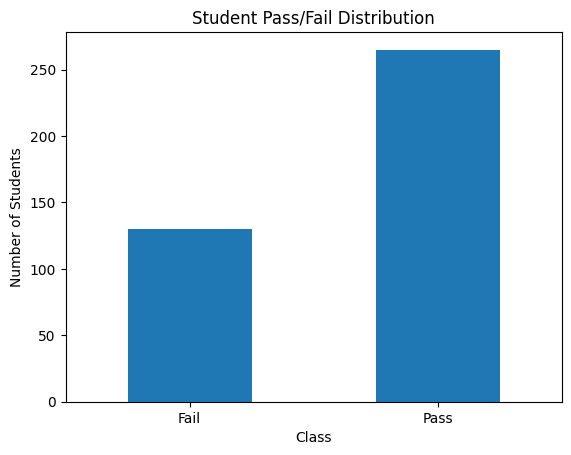

In [14]:
student_data["Pass_Fail"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks([0, 1], ["Fail", "Pass"], rotation=0)
plt.xlabel("Class")
plt.ylabel("Number of Students")
plt.title("Student Pass/Fail Distribution")
plt.show()

In [15]:
X = student_data[
    ["G1", "G2", "studytime", "absences"]
].to_numpy(dtype=float)

y = student_data["Pass_Fail"].to_numpy(dtype=float)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (395, 4)
Target shape: (395,)


In [16]:
print("Missing values in input data:", np.isnan(X).sum())
print("Missing values in target:", np.isnan(y).sum())

Missing values in input data: 0
Missing values in target: 0


## Split and Normalize the Data

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


In [18]:
# Calculate scaling parameters from training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

# Avoid division by zero
std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Feature normalization completed!")

Feature normalization completed!


## Build the Single-Layer ANN

In [19]:
## Initialize weights and bias

number_of_features = X_train_scaled.shape[1]

weights = np.random.randn(number_of_features) * 0.01
bias = 0.0

print("Initial weights:", weights)
print("Initial bias:", bias)

Initial weights: [ 0.00209978 -0.0037637  -0.00121159 -0.00202497]
Initial bias: 0.0


In [20]:
## Define sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [21]:
## Define the prediction function
def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)

In [22]:
## Define loss function
def calculate_loss(y_true, y_pred):
    epsilon = 1e-10

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

## Train the ANN Using Gradient Descent

In [23]:
## Train the neural network 
learning_rate = 0.05
epochs = 5000

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    predictions = predict_probability(
        X_train_scaled,
        weights,
        bias
    )

    # Calculate loss
    loss = calculate_loss(
        y_train,
        predictions
    )

    loss_history.append(loss)

    # Calculate prediction errors
    errors = predictions - y_train

    # Calculate gradients
    dw = np.dot(
        X_train_scaled.T,
        errors
    ) / len(y_train)

    db = np.mean(errors)

    # Update weights and bias
    weights -= learning_rate * dw
    bias -= learning_rate * db

print("Training completed!")
print("Final weights:", weights)
print("Final bias:", bias)
print("Final training loss:", loss_history[-1])

Training completed!
Final weights: [ 1.3201101   4.69438799 -0.25297294 -0.28723211]
Final bias: 2.6948683095614765
Final training loss: 0.1727360360244814


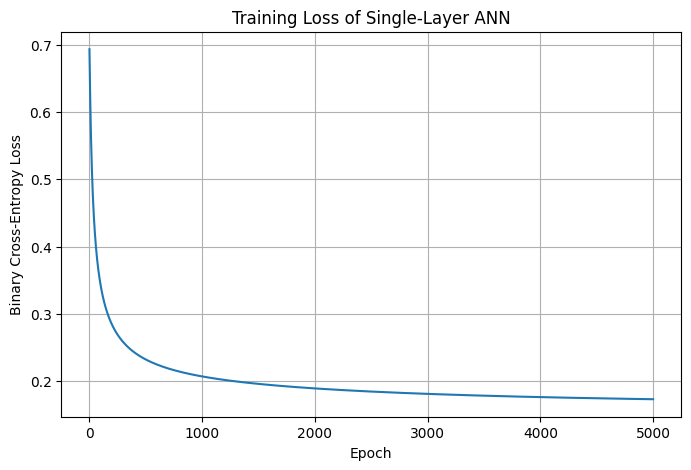

In [24]:
## Plot the training loss 
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss of Single-Layer ANN")

plt.grid(True)
plt.show()

## Make Predictions

In [25]:
## Make predictions 
y_prob = predict_probability(
    X_test_scaled,
    weights,
    bias
)

print("First 10 predicted probabilities:")
print(np.round(y_prob[:10], 3))

First 10 predicted probabilities:
[0.996 0.132 0.992 0.949 1.    0.993 1.    0.18  0.685 1.   ]


In [26]:
y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:")
print(y_test[:10].astype(int))

print("\nPredicted labels:")
print(y_pred[:10])

Actual labels:
[1 0 1 1 1 1 1 0 1 1]

Predicted labels:
[1 0 1 1 1 1 1 0 1 1]


## Evaluate the Model

In [27]:
accuracy = np.mean(y_pred == y_test) * 100

print("Test Accuracy:", round(accuracy, 2), "%")

Test Accuracy: 87.34 %


In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test.astype(int),
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[23  3]
 [ 7 46]]


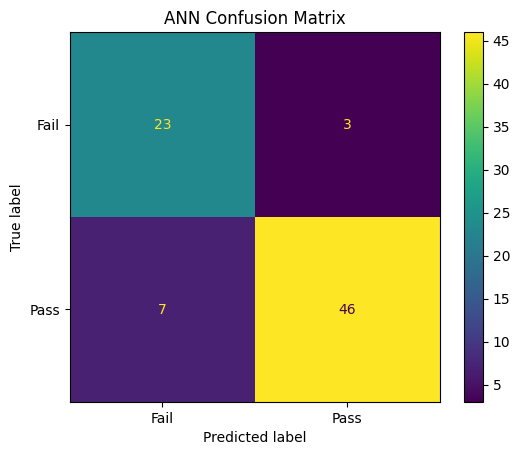

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

display.plot()

plt.title("ANN Confusion Matrix")
plt.show()

In [30]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test.astype(int),
        y_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Fail       0.77      0.88      0.82        26
        Pass       0.94      0.87      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.88      0.86        79
weighted avg       0.88      0.87      0.88        79



## Test a New Student

In [31]:
new_student = np.array([[12, 14, 3, 2]], dtype=float)

# Use the training-set normalization parameters
new_student_scaled = (new_student - mean) / std

# Predict probability
pass_probability = predict_probability(
    new_student_scaled,
    weights,
    bias
)[0]

# Predict class
prediction = int(pass_probability >= 0.5)

print("New student details:")
print("G1 = 12, G2 = 14, Study time = 3, Absences = 2")

print("\nPredicted probability of passing:",
      round(pass_probability, 3))

if prediction == 1:
    print("Predicted result: PASS")
else:
    print("Predicted result: FAIL")

New student details:
G1 = 12, G2 = 14, Study time = 3, Absences = 2

Predicted probability of passing: 0.999
Predicted result: PASS


## Display Learned Parameters

In [32]:
print("Final trained weights:")

for i, weight in enumerate(weights):
    print(f"Weight {i + 1}: {weight:.4f}")

print(f"\nFinal bias: {bias:.4f}")

Final trained weights:
Weight 1: 1.3201
Weight 2: 4.6944
Weight 3: -0.2530
Weight 4: -0.2872

Final bias: 2.6949


## Conclusion : 
A single-layer Artificial Neural Network was implemented successfully using Python and NumPy for student Pass/Fail classification. The Student Performance dataset was loaded from a CSV file and preprocessed before training. The sigmoid activation function and binary cross-entropy loss were used, and the weights and bias were updated using gradient descent. The trained network predicted student outcomes, and its performance was evaluated using accuracy, a confusion matrix, precision, recall, and F1-score.
